# Predicting 30-day readmission of diabetic patients

**Applying and Interpreting Machine Learning — group project, Step 3 (build the ML) · Group 4**

> *We predict whether a diabetic patient is **readmitted to the hospital within 30 days of discharge**, for patients treated for diabetes in US hospitals, using information that is available **at the moment of discharge**.*

Data: UCI *Diabetes 130-US Hospitals for Years 1999–2008* (`data/diabetic_data.csv`, one row = one inpatient encounter).

**How the notebook follows the grading checklist**

| Checklist item | Where / how |
|---|---|
| Preprocessing is fit on the training data only | Section 6: all scaling / encoding sits inside a scikit-learn `Pipeline`, so it is re-fitted inside every CV fold and on the training set only |
| No feature gives away the outcome | Section 3: `readmitted`, `encounter_id`, `patient_nbr` are not features; deaths/hospice are excluded; every feature is known at discharge |
| Test set is used once, at the end | Section 12 is the first and only place where `X_test` / `y_test` are touched |
| Runs top to bottom, reproducible | All seeds fixed (`SEED = 42`); runtime ≈ 15–25 min on a free Colab CPU |
| Code logic matches the slides | Sections follow the 6 slide points of Step 4 (see the table in Section 13) |

**Contents:** 0 Setup · 1 Load · 2 Outcome and exclusions · 3 Features · 4 Group-based split · 5 Metrics and baselines · 6 Preprocessing · 7 Logistic regression · 8 Random forest · 9 Gradient boosting · 10 Model comparison (CV) · 11 Operating threshold · 12 **Final test evaluation** · 13 Error analysis · 14 What drives the predictions · 15 Limits

## 0. Setup and configuration

Everything a teammate might want to change is in the next cell.

In [ ]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt




import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore", category=FutureWarning)                       # sklearn 1.8+ deprecation chatter only
warnings.filterwarnings("ignore", message="Found unknown categories")            # rare categories unseen in a fold -> pooled as 'infrequent' (intended)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

# ----------------------------- configuration ------------------------------------------------
SEED = 42                    # one seed for every random choice
OUTCOME = "30day"            # "30day": readmitted <30 days (1) vs. later / never (0)   <- main choice
                             # "any"  : readmitted at all (1) vs. never readmitted (0)  <- the 'balanced' option
USE_RACE_AS_FEATURE = False  # race is used for the fairness audit (Section 13) but not as a model input
N_FOLDS = 5                  # cross-validation folds (stratified, grouped by patient)
COST_FN_OVER_FP = 5          # ASSUMPTION: a missed readmission costs 5x a wasted follow-up (discuss in the group!)
FLAG_SHARE = 0.20            # ASSUMPTION: staff can follow up with the 20% highest-risk patients
N_BOOT = 1000                # bootstrap draws for the test-set confidence intervals
QUICK = False                # True = tiny grids, only to debug the notebook. Keep False for the real run.

RESULTS = Path("results"); (RESULTS / "figures").mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

# chart colours (validated categorical palette, fixed order) + neutral grey for baselines
C_BLUE, C_ORANGE, C_AQUA, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10})

SKL_NEW = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


## 1. Load the data

`?` marks a missing value in the raw file. We read it explicitly as missing; the string `None` in the lab-test columns is a real category ("test not performed") and must **not** be treated as missing.

In [2]:
def find_data():
    for p in ["data/diabetic_data.csv", "diabetic_data.csv", "/content/data/diabetic_data.csv", "/content/diabetic_data.csv"]:
        if Path(p).exists():
            return p
    raise FileNotFoundError("diabetic_data.csv not found. Put it in ./data/ (the repository already contains it) "
                            "or download it from https://archive.ics.uci.edu/dataset/296 .")

raw = pd.read_csv(find_data(), na_values=["?"], keep_default_na=False, low_memory=False)
print("Raw table:", raw.shape[0], "encounters,", raw["patient_nbr"].nunique(), "patients,", raw.shape[1], "columns")
assert raw["encounter_id"].is_unique
raw["readmitted"].value_counts()

Raw table: 101766 encounters, 71518 patients, 50 columns


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

## 2. Outcome and exclusions

**Outcome.** The main outcome is *readmitted within 30 days* (`<30`) vs. everything else — the standard definition in hospital quality reporting, and the one a nurse can act on. A switch in Section 0 (`OUTCOME = "any"`) gives the alternative "readmitted at all vs. never" for comparison.

**Exclusions.** Patients who died in hospital or were discharged to hospice cannot be readmitted, so they are not meaningful negatives (`discharge_disposition_id` 11, 13, 14, 19, 20, 21). Three rows with gender `Unknown/Invalid` are dropped.

In [3]:
DEATH_OR_HOSPICE = [11, 13, 14, 19, 20, 21]

df = raw[~raw["discharge_disposition_id"].isin(DEATH_OR_HOSPICE)]
n_excl = len(raw) - len(df)
df = df[df["gender"] != "Unknown/Invalid"].copy()

y_all = (df["readmitted"] == "<30").astype(int) if OUTCOME == "30day" else (df["readmitted"] != "NO").astype(int)
groups_all = df["patient_nbr"]          # used ONLY to keep the same patient on one side of every split

print(f"Excluded (died / hospice): {n_excl} encounters")
print(f"Analysis sample: {len(df):,} encounters from {groups_all.nunique():,} patients")
print(f"Outcome = '{OUTCOME}': positive rate {y_all.mean():.3%}  "
      f"(30-day readmission: {(df['readmitted']=='<30').mean():.1%}, any readmission: {(df['readmitted']!='NO').mean():.1%})")

Excluded (died / hospice): 2423 encounters
Analysis sample: 99,340 encounters from 69,987 patients
Outcome = '30day': positive rate 11.389%  (30-day readmission: 11.4%, any readmission: 47.1%)


## 3. Features (all known at discharge) and feature blocks

The prediction moment is **discharge**. Every feature below describes the patient's history or the stay that is ending; none comes from after discharge.

Features are organised in **blocks** (used again in Section 14 to ask *which kind of information matters*):

| Block | Content |
|---|---|
| Demographics | age (bracket mid-point), gender, race |
| Admission context | admission type and source, payer, medical specialty |
| Prior utilisation | outpatient / emergency / inpatient visits in the year before this admission |
| Current stay | days in hospital, lab tests, procedures, medications, number of diagnoses, discharge destination |
| Diagnoses | primary / secondary / tertiary diagnosis, grouped from ICD-9 codes (Strack et al., 2014) |
| Lab tests | glucose serum test and HbA1c result (mostly "not measured") |
| Diabetes medication | 21 drug columns (No / Steady / Up / Down), "medication changed", "on diabetes medication", counts |

**Deliberately not used:** `readmitted` (the outcome), `patient_nbr` (grouping only), `encounter_id` (could encode calendar time), `weight` (97% missing), `examide` / `citoglipton` (constant).

All transformations in this section are **row-by-row** (recoding, grouping, counting). Nothing is learned from the data here, so doing them before the split is not leakage. Everything data-dependent (scaling, one-hot categories) is in Section 6.

In [4]:
MED_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide", "glipizide",
            "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol", "troglitazone",
            "tolazamide", "insulin", "glyburide-metformin", "glipizide-metformin", "glimepiride-pioglitazone",
            "metformin-rosiglitazone", "metformin-pioglitazone"]          # examide, citoglipton: constant -> dropped

AGE_MID = {f"[{a}-{a+10})": a + 5 for a in range(0, 100, 10)}

def icd9_group(code):
    """ICD-9 -> 9 broad groups, following Strack et al. (2014)."""
    if pd.isna(code): return "Missing"
    c = str(code)
    if c[0] in "VE": return "Other"
    try: n = int(float(c))
    except ValueError: return "Other"
    if n == 250: return "Diabetes"
    if 390 <= n <= 459 or n == 785: return "Circulatory"
    if 460 <= n <= 519 or n == 786: return "Respiratory"
    if 520 <= n <= 579 or n == 787: return "Digestive"
    if 580 <= n <= 629 or n == 788: return "Genitourinary"
    if 800 <= n <= 999: return "Injury"
    if 710 <= n <= 739: return "Musculoskeletal"
    if 140 <= n <= 239: return "Neoplasms"
    return "Other"

def group_admission_source(i):                       # codes: see data/IDS_mapping.csv
    if i in (1, 2, 3): return "Referral"
    if i == 7: return "Emergency room"
    if i in (4, 5, 6, 10, 18, 22, 25, 26): return "Transfer from other facility"
    if i in (9, 15, 17, 20, 21): return "Unknown"
    return "Other"

def group_discharge(i):
    if i == 1: return "Home"
    if i in (6, 8): return "Home with health service"
    if i in (3, 4, 23, 24): return "Nursing / long-term care"
    if i == 22: return "Rehabilitation"
    if i == 7: return "Left against medical advice"
    if i in (18, 25, 26): return "Unknown"
    return "Other facility / transfer"

def build_features(d):
    X = pd.DataFrame(index=d.index)
    # demographics
    X["age_num"] = d["age"].map(AGE_MID)
    X["gender"] = d["gender"]
    X["race"] = d["race"].fillna("Unknown")
    # admission context
    X["admission_type"] = d["admission_type_id"].map({1: "Emergency", 2: "Urgent", 3: "Elective"}).fillna("Other/unknown")
    X["admission_source"] = d["admission_source_id"].map(group_admission_source)
    X["payer_code"] = d["payer_code"].fillna("Unknown")
    X["medical_specialty"] = d["medical_specialty"].fillna("Unknown")
    # prior utilisation (previous 12 months)
    for c in ["number_outpatient", "number_emergency", "number_inpatient"]:
        X[c] = d[c]
    X["prior_visits_total"] = d[["number_outpatient", "number_emergency", "number_inpatient"]].sum(axis=1)
    # current stay
    for c in ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses"]:
        X[c] = d[c]
    X["discharge_group"] = d["discharge_disposition_id"].map(group_discharge)
    # diagnoses
    for k in (1, 2, 3):
        X[f"diag_{k}_grp"] = d[f"diag_{k}"].map(icd9_group)
    # lab tests ("None" = not measured)
    X["max_glu_serum"] = d["max_glu_serum"].replace({"None": "Not measured"})
    X["A1Cresult"] = d["A1Cresult"].replace({"None": "Not measured"})
    # diabetes medication
    for c in MED_COLS:
        X[c] = d[c]
    X["change"] = d["change"]
    X["diabetesMed"] = d["diabetesMed"]
    X["n_meds_active"] = (d[MED_COLS] != "No").sum(axis=1)
    X["n_med_changes"] = d[MED_COLS].isin(["Up", "Down"]).sum(axis=1)
    return X

X_all = build_features(df)
assert not X_all.isna().any().any(), "unexpected missing values"

BLOCKS = {
    "Demographics":        ["age_num", "gender", "race"],
    "Admission context":   ["admission_type", "admission_source", "payer_code", "medical_specialty"],
    "Prior utilisation":   ["number_outpatient", "number_emergency", "number_inpatient", "prior_visits_total"],
    "Current stay":        ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                            "number_diagnoses", "discharge_group"],
    "Diagnoses":           ["diag_1_grp", "diag_2_grp", "diag_3_grp"],
    "Lab tests":           ["max_glu_serum", "A1Cresult"],
    "Diabetes medication": MED_COLS + ["change", "diabetesMed", "n_meds_active", "n_med_changes"],
}
if not USE_RACE_AS_FEATURE:
    BLOCKS["Demographics"].remove("race")

NUM_COLS = ["age_num", "number_outpatient", "number_emergency", "number_inpatient", "prior_visits_total",
            "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses",
            "n_meds_active", "n_med_changes"]
COUNT_COLS = ["number_outpatient", "number_emergency", "number_inpatient", "prior_visits_total"]   # heavy-tailed
MODEL_COLS = [c for cols in BLOCKS.values() for c in cols]
CAT_COLS = [c for c in MODEL_COLS if c not in NUM_COLS]
assert set(MODEL_COLS) <= set(X_all.columns) and len(MODEL_COLS) == len(set(MODEL_COLS))

print(f"{len(MODEL_COLS)} model inputs: {len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical "
      f"(race used as input: {USE_RACE_AS_FEATURE})")
for b, cols in BLOCKS.items():
    print(f"  {b:<20s} {len(cols):>2d} columns")
X_all[["age_num", "admission_type", "discharge_group", "diag_1_grp", "number_inpatient", "n_meds_active"]].head()

46 model inputs: 12 numeric + 34 categorical (race used as input: False)
  Demographics          2 columns
  Admission context     4 columns
  Prior utilisation     4 columns
  Current stay          6 columns
  Diagnoses             3 columns
  Lab tests             2 columns
  Diabetes medication  25 columns


,age_num,admission_type,discharge_group,diag_1_grp,number_inpatient,n_meds_active
0,5,Other/unknown,Unknown,Diabetes,0,0
1,15,Emergency,Home,Other,0,1
2,25,Emergency,Home,Other,1,1
3,35,Emergency,Home,Other,0,1
4,45,Emergency,Home,Neoplasms,0,2


## 4. Group-based split (patients never shared between sets)

Many patients have several encounters (up to 40). A random split would put the *same patient* in training and test, and the model could recognise the patient — an over-optimistic estimate. Therefore:

1. **Train / test (80 / 20):** `StratifiedGroupKFold` with `groups = patient_nbr`; the first fold is the test set. This keeps patients together **and** keeps the share of readmissions similar in both sets.
2. **Cross-validation inside the training set:** the same `StratifiedGroupKFold`, grouped by patient again. The fold indices are computed **once** and reused for every model, so all models are compared on identical folds.

A time-based split is not possible (the data has no admission dates). The test set is not touched again until Section 12.

In [5]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)       # 5 folds -> first fold = 20% test
train_idx, test_idx = next(splitter.split(X_all, y_all, groups_all))

X_train, y_train, g_train = X_all.iloc[train_idx], y_all.iloc[train_idx], groups_all.iloc[train_idx]
X_test,  y_test,  g_test  = X_all.iloc[test_idx],  y_all.iloc[test_idx],  groups_all.iloc[test_idx]   # <- untouched until Section 12

assert set(g_train).isdisjoint(set(g_test)), "a patient appears in both train and test!"

# cross-validation folds on the training set (also grouped by patient), computed once
cv_splits = list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_train, y_train, g_train))
for tr, va in cv_splits:
    assert set(g_train.iloc[tr]).isdisjoint(set(g_train.iloc[va]))

summary = pd.DataFrame({
    "encounters": [len(y_train), len(y_test)],
    "patients": [g_train.nunique(), g_test.nunique()],
    "positive rate": [y_train.mean(), y_test.mean()]}, index=["train", "test"])
summary["positive rate"] = summary["positive rate"].map("{:.2%}".format)
summary

,encounters,patients,positive rate
train,79473,56036,11.39%
test,19867,13951,11.39%


## 5. Metrics and baselines

**Which metric?** Only ≈11% of encounters are positive, so *accuracy is misleading* (a rule that never flags anyone is 89% "accurate"). We therefore

- select models by **AUPRC** (average precision; threshold-free, honest under imbalance — the no-skill level equals the base rate), and also report ROC-AUC for reference;
- judge the **decision** with precision and recall at an operating threshold chosen from the cost of errors: a missed readmission (false negative) is much more costly than an unnecessary follow-up call (false positive). The cost ratio is an assumption set in Section 0 and varied in Section 11.

**Baselines (what someone would do without ML)**

1. *Majority class:* flag nobody.
2. *Clinical rule:* flag everyone with at least one inpatient admission in the previous year (`number_inpatient >= 1`).

Neither baseline is fitted, so their cross-validated score is just their score on each validation fold.

In [6]:
def flag_top_share(score, share):
    """Boolean flags for the `share` highest scores (ties broken by position)."""
    n = int(round(share * len(score)))
    flags = np.zeros(len(score), dtype=bool)
    flags[np.argsort(-np.asarray(score), kind="stable")[:n]] = True
    return flags

def confusion_counts(y, flags):
    y = np.asarray(y).astype(bool); flags = np.asarray(flags).astype(bool)
    return dict(TP=int((y & flags).sum()), FP=int((~y & flags).sum()), FN=int((y & ~flags).sum()), TN=int((~y & ~flags).sum()))

def operating_metrics(y, flags, cost_ratio=COST_FN_OVER_FP):
    c = confusion_counts(y, flags)
    n = len(flags)
    prec = c["TP"] / (c["TP"] + c["FP"]) if (c["TP"] + c["FP"]) else np.nan
    rec = c["TP"] / (c["TP"] + c["FN"])
    return {"flagged share": (c["TP"] + c["FP"]) / n, "precision": prec, "recall": rec,
            "cost per 100 patients": 100 * (cost_ratio * c["FN"] + c["FP"]) / n, **c}

def ap(y, s, w=None):
    return average_precision_score(y, s, sample_weight=w)

# --- baselines scored on the CV validation folds (training data only) ---
rule_train = (X_train["number_inpatient"] >= 1).to_numpy()
base_majority_folds = np.array([y_train.iloc[va].mean() for _, va in cv_splits])          # AUPRC of a constant score = base rate
base_rule_folds = np.array([ap(y_train.iloc[va], rule_train[va]) for _, va in cv_splits])

print(f"Base rate (training): {y_train.mean():.3%}  -> accuracy of 'flag nobody': {1 - y_train.mean():.1%}")
print(f"Clinical rule flags {rule_train.mean():.1%} of training encounters; "
      f"precision {y_train[rule_train].mean():.1%}, recall {y_train[rule_train].sum() / y_train.sum():.1%}")
print(f"CV AUPRC  majority: {base_majority_folds.mean():.4f}   rule: {base_rule_folds.mean():.4f} ± {base_rule_folds.std(ddof=1):.4f}")

Base rate (training): 11.389%  -> accuracy of 'flag nobody': 88.6%
Clinical rule flags 33.2% of training encounters; precision 17.0%, recall 49.6%
CV AUPRC  majority: 0.1139   rule: 0.1417 ± 0.0022


## 6. Preprocessing (inside the pipeline, so it is fitted on training data only)

- **Numeric:** the heavy-tailed visit counts get `log(1 + x)`; for the *linear* model all numeric inputs are standardised (needed for the penalty to treat features equally). Tree models need no scaling.
- **Categorical:** one-hot encoding; categories with less than 1% of the *training* rows are pooled into an "infrequent" level; unseen categories at prediction time fall into it as well.

Because these steps are `Pipeline` components, `fit` is called only on the data of the current training fold — never on validation or test rows.

In [7]:
def make_pre(kind):
    ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, drop="if_binary", sparse_output=False)
    if kind == "linear":
        other_num = [c for c in NUM_COLS if c not in COUNT_COLS]
        ct = ColumnTransformer([
            ("cnt", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                              ("sc", StandardScaler())]), COUNT_COLS),
            ("num", StandardScaler(), other_num),
            ("cat", ohe, CAT_COLS)])
    else:
        ct = ColumnTransformer([("num", "passthrough", NUM_COLS), ("cat", ohe, CAT_COLS)])
    # VarianceThreshold removes columns that are constant in the training data (e.g. a drug that is never used there)
    return Pipeline([("encode", ct), ("drop_constant", VarianceThreshold())])

def cv_report(search):
    """Fold-by-fold CV scores of the best hyper-parameter setting."""
    i = search.best_index_
    folds = np.array([search.cv_results_[f"split{k}_test_score"][i] for k in range(N_FOLDS)])
    return {"estimator": search.best_estimator_, "params": search.best_params_, "folds": folds,
            "mean": folds.mean(), "sd": folds.std(ddof=1)}

models = {}      # name -> dict(estimator = fitted on the full training set, folds, mean, sd, params)
print("Preprocessing ready. Input columns:", len(MODEL_COLS))

Preprocessing ready. Input columns: 46


## 7. Model 1 — regularised logistic regression (Lasso and Ridge)

Interpretable benchmark: readmission probability as a logistic function of a weighted sum of features. The penalty strength `C` (= 1/λ, **smaller = stronger penalty**) is tuned by **grouped 5-fold CV on AUPRC**, separately for the Lasso (L1, drops features) and the Ridge (L2, shrinks them). The better of the two goes forward.

Lasso (L1): best C = 0.1, CV AUPRC = 0.2088
Ridge (L2): best C = 0.03, CV AUPRC = 0.2086
-> selected: Lasso  (159s)


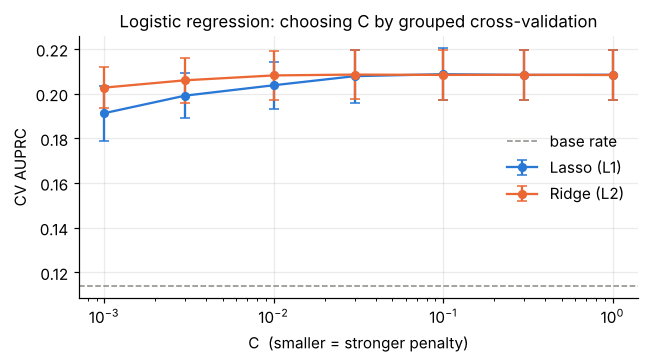

In [8]:
def make_logit(C, penalty):
    """Works across scikit-learn versions (>=1.8 uses l1_ratio, older versions use penalty)."""
    if penalty == "l2":
        return LogisticRegression(C=C, max_iter=3000)
    if SKL_NEW:
        return LogisticRegression(C=C, l1_ratio=1, solver="liblinear", max_iter=3000)
    return LogisticRegression(C=C, penalty="l1", solver="liblinear", max_iter=3000)

C_GRID = [0.003, 0.03, 0.3] if QUICK else [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]
t0 = time.time()
logit_searches = {}
for penalty in ["l1", "l2"]:
    pipe = Pipeline([("pre", make_pre("linear")), ("clf", make_logit(1.0, penalty))])
    gs = GridSearchCV(pipe, {"clf__C": C_GRID}, scoring="average_precision", cv=cv_splits, n_jobs=-1, refit=True)
    logit_searches[penalty] = gs.fit(X_train, y_train)
    print(f"{'Lasso (L1)' if penalty == 'l1' else 'Ridge (L2)'}: best C = {gs.best_params_['clf__C']}, CV AUPRC = {gs.best_score_:.4f}")

best_pen = max(logit_searches, key=lambda p: logit_searches[p].best_score_)
models["Logistic regression"] = cv_report(logit_searches[best_pen])
models["Logistic regression"]["penalty"] = best_pen
print(f"-> selected: {'Lasso' if best_pen == 'l1' else 'Ridge'}  ({time.time() - t0:.0f}s)")

fig, ax = plt.subplots(figsize=(6, 3.4))
for pen, col, lab in [("l1", C_BLUE, "Lasso (L1)"), ("l2", C_ORANGE, "Ridge (L2)")]:
    r = logit_searches[pen].cv_results_
    ax.errorbar(C_GRID, r["mean_test_score"], yerr=r["std_test_score"], marker="o", ms=5, lw=1.5, capsize=3, color=col, label=lab)
ax.axhline(y_train.mean(), color=C_GREY, ls="--", lw=1, label="base rate")
ax.set_xscale("log"); ax.set_xlabel("C  (smaller = stronger penalty)"); ax.set_ylabel("CV AUPRC")
ax.set_title("Logistic regression: choosing C by grouped cross-validation"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "cv_logit.png", dpi=150); plt.show()

## 8. Model 2 — random forest

Averages many deep trees grown on bootstrap samples; can capture non-linear effects and interactions without being told. Tuned by the same grouped CV:

- `min_samples_leaf` — minimum encounters per leaf (large = smoother, simpler trees; the main guard against overfitting here),
- `max_features` — features considered per split (smaller = more decorrelated trees).

The number of trees is fixed: more trees never overfit, they only cost time.

In [9]:
t0 = time.time()
rf_grid = {"clf__min_samples_leaf": [30] if QUICK else [10, 30, 100],
           "clf__max_features": ["sqrt"] if QUICK else ["sqrt", 0.15]}
rf_pipe = Pipeline([("pre", make_pre("tree")),
                    ("clf", RandomForestClassifier(n_estimators=100 if QUICK else 200, n_jobs=-1, random_state=SEED))])
rf_search = GridSearchCV(rf_pipe, rf_grid, scoring="average_precision", cv=cv_splits, n_jobs=1, refit=True).fit(X_train, y_train)
models["Random forest"] = cv_report(rf_search)
print("Best:", rf_search.best_params_, f"| CV AUPRC = {rf_search.best_score_:.4f}  ({time.time() - t0:.0f}s)")
pd.DataFrame(rf_search.cv_results_)[["param_clf__min_samples_leaf", "param_clf__max_features", "mean_test_score", "std_test_score"]] \
  .rename(columns=lambda c: c.replace("param_clf__", "")).round(4)

Best: {'clf__max_features': 0.15, 'clf__min_samples_leaf': 10} | CV AUPRC = 0.2278  (262s)


,min_samples_leaf,max_features,mean_test_score,std_test_score
0,10,sqrt,0.2256,0.0142
1,30,sqrt,0.2228,0.0135
2,100,sqrt,0.2176,0.0124
3,10,0.15,0.2278,0.0137
4,30,0.15,0.2259,0.0128
5,100,0.15,0.2212,0.0119


## 9. Model 3 — gradient boosting (XGBoost)

Boosting grows many **small** trees one after another, each correcting the errors left by the previous ones (slides L5b). It is the usual top performer on tabular data, but it has more knobs than a forest, so it is tuned by **randomised search with the same grouped CV folds**:

- `learning_rate` (shrinkage), `n_estimators` (number of trees), `max_depth` (tree complexity),
- regularisation / sampling: `min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda`.

**Backend.** The notebook uses **XGBoost** if it is installed and works (`pip install xgboost`; preinstalled on Colab). If not, it falls back to scikit-learn's `HistGradientBoostingClassifier`, which implements the same histogram-based gradient boosting idea, so the notebook always runs. The cell prints which backend was used.

In [10]:
def get_boosting():
    """Return (name, estimator, search space). Tries XGBoost, falls back to sklearn's HistGradientBoosting."""
    try:
        from xgboost import XGBClassifier
        # smoke test: does XGBoost work inside a sklearn Pipeline + RandomizedSearchCV in this environment?
        rs = np.random.RandomState(0); Xs = rs.rand(300, 6); ys = (rs.rand(300) > 0.7).astype(int)
        RandomizedSearchCV(Pipeline([("sc", StandardScaler()), ("clf", XGBClassifier(n_estimators=5, n_jobs=1))]),
                           {"clf__max_depth": [2, 3]}, n_iter=1, cv=2, scoring="average_precision").fit(Xs, ys)
        est = XGBClassifier(objective="binary:logistic", tree_method="hist", n_jobs=-1, random_state=SEED, verbosity=0)
        space = {"clf__n_estimators": [150, 300, 500], "clf__learning_rate": [0.02, 0.05, 0.1],
                 "clf__max_depth": [2, 3, 4, 5], "clf__min_child_weight": [5, 20, 50],
                 "clf__subsample": [0.7, 0.9], "clf__colsample_bytree": [0.5, 0.8], "clf__reg_lambda": [1, 10, 50]}
        return "XGBoost", est, space
    except Exception as e:
        print(f"XGBoost not usable here ({type(e).__name__}) -> using sklearn HistGradientBoostingClassifier instead")
        est = HistGradientBoostingClassifier(random_state=SEED)
        space = {"clf__max_iter": [150, 300, 500], "clf__learning_rate": [0.02, 0.05, 0.1],
                 "clf__max_depth": [2, 3, 4, 5], "clf__min_samples_leaf": [20, 50, 100],
                 "clf__l2_regularization": [0, 1, 10, 50]}
        return "HistGradientBoosting", est, space

BOOST_NAME, boost_est, boost_space = get_boosting()
print("Boosting backend:", BOOST_NAME)

t0 = time.time()
boost_pipe = Pipeline([("pre", make_pre("tree")), ("clf", boost_est)])
boost_search = RandomizedSearchCV(boost_pipe, boost_space, n_iter=3 if QUICK else 12, scoring="average_precision",
                                  cv=cv_splits, n_jobs=1, refit=True, random_state=SEED).fit(X_train, y_train)
models[BOOST_NAME] = cv_report(boost_search)
print("Best:", {k.replace("clf__", ""): v for k, v in boost_search.best_params_.items()})
print(f"CV AUPRC = {boost_search.best_score_:.4f}  ({time.time() - t0:.0f}s)")

XGBoost not usable here (ModuleNotFoundError) -> using sklearn HistGradientBoostingClassifier instead
Boosting backend: HistGradientBoosting
Best: {'min_samples_leaf': 20, 'max_iter': 300, 'max_depth': 5, 'learning_rate': 0.02, 'l2_regularization': 0}
CV AUPRC = 0.2304  (311s)


## 10. Model comparison on the validation folds (no test data involved)

All models and both baselines are scored on **the same grouped folds**. Because folds overlap in their training data, the standard error is a rough lower bound for the true uncertainty; the **paired fold-by-fold differences** are more informative than comparing two means. **The model is chosen here — on cross-validation only.**

Base rate (training): 0.1139
SELECTED by CV AUPRC: HistGradientBoosting

HistGradientBoosting minus Random forest: mean +0.0026, SD 0.0042, wins 4 of 5 folds
HistGradientBoosting minus Logistic regression: mean +0.0217, SD 0.0047, wins 5 of 5 folds
HistGradientBoosting minus Baseline: clinical rule: mean +0.0887, SD 0.0149, wins 5 of 5 folds

Note: HistGradientBoosting beats Random forest by only 0.0026 AUPRC, less than one standard error (0.0075). The two are practically tied; the selection rule (highest CV mean, fixed in advance) simply picks one.


,CV AUPRC (mean),SD across folds,SE (SD/sqrt(5)),lift over base rate
Baseline: majority class,0.1139,0.0000,0.0000,1.0000
Baseline: clinical rule,0.1417,0.0022,0.0010,1.2442
Logistic regression,0.2088,0.0129,0.0058,1.8330
Random forest,0.2278,0.0153,0.0069,2.0005
HistGradientBoosting,0.2304,0.0168,0.0075,2.0235


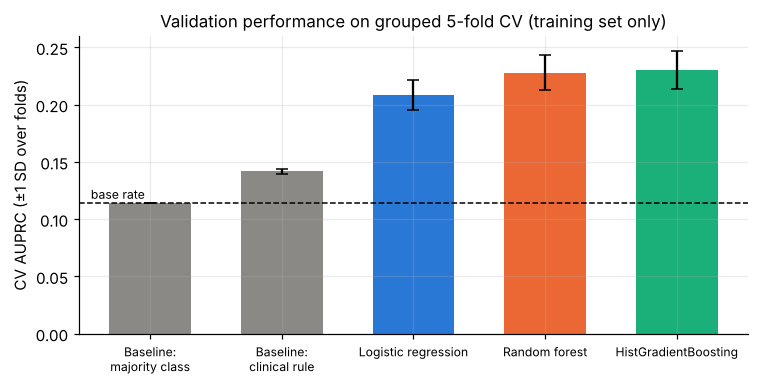

In [11]:
cv_table = pd.DataFrame({
    "Baseline: majority class": base_majority_folds,
    "Baseline: clinical rule": base_rule_folds,
    **{name: m["folds"] for name, m in models.items()}}, index=[f"fold {k+1}" for k in range(N_FOLDS)])

cv_summary = pd.DataFrame({"CV AUPRC (mean)": cv_table.mean(), "SD across folds": cv_table.std(ddof=1),
                           "SE (SD/sqrt(5))": cv_table.std(ddof=1) / np.sqrt(N_FOLDS)})
cv_summary["lift over base rate"] = cv_summary["CV AUPRC (mean)"] / y_train.mean()
cv_summary.round(4).to_csv(RESULTS / "cv_summary.csv")

ML_NAMES = list(models)
SELECTED = max(ML_NAMES, key=lambda n: models[n]["mean"])
print(f"Base rate (training): {y_train.mean():.4f}")
print(f"SELECTED by CV AUPRC: {SELECTED}\n")

# paired differences against the runner-up and the clinical rule
others = sorted([n for n in ML_NAMES if n != SELECTED], key=lambda n: -models[n]["mean"])
for other in others + ["Baseline: clinical rule"]:
    diff = cv_table[SELECTED] - cv_table[other]
    print(f"{SELECTED} minus {other}: mean {diff.mean():+.4f}, SD {diff.std(ddof=1):.4f}, wins {(diff > 0).sum()} of {N_FOLDS} folds")
gap = models[SELECTED]["mean"] - models[others[0]]["mean"]
se_sel = cv_table[SELECTED].std(ddof=1) / np.sqrt(N_FOLDS)
if gap < se_sel:
    print(f"\nNote: {SELECTED} beats {others[0]} by only {gap:.4f} AUPRC, less than one standard error ({se_sel:.4f}). "
          f"The two are practically tied; the selection rule (highest CV mean, fixed in advance) simply picks one.")

colors = {"Baseline: majority class": C_GREY, "Baseline: clinical rule": C_GREY}
palette = [C_BLUE, C_ORANGE, C_AQUA]
colors.update({n: palette[i] for i, n in enumerate(ML_NAMES)})
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(range(len(cv_summary)), cv_summary["CV AUPRC (mean)"], yerr=cv_summary["SD across folds"], capsize=4,
       color=[colors[n] for n in cv_summary.index], width=0.62)
ax.axhline(y_train.mean(), color="black", ls="--", lw=1)
ax.text(-0.45, y_train.mean() + 0.004, "base rate", ha="left", fontsize=8)
ax.set_xticks(range(len(cv_summary))); ax.set_xticklabels([n.replace("Baseline: ", "Baseline:\n") for n in cv_summary.index], fontsize=8)
ax.set_ylabel("CV AUPRC (±1 SD over folds)"); ax.set_title("Validation performance on grouped 5-fold CV (training set only)")
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "cv_comparison.png", dpi=150); plt.show()
cv_summary.round(4)

## 11. Choosing the operating threshold (still without test data)

A probability is not a decision. We need a cut-off above which a patient is flagged for follow-up. The cut-off is chosen on **out-of-fold predictions of the training set** (each training encounter scored by a model that did not see its patient), by minimising

$$\text{cost} = C_{FN}\cdot FN + C_{FP}\cdot FP, \qquad C_{FN}/C_{FP} = \text{COST\_FN\_OVER\_FP}.$$

The cost ratio is an **assumption** — in a real project it comes from the hospital. The table below shows how strongly the answer depends on it: the higher the cost of a missed readmission, the more patients must be flagged.

In [12]:
t0 = time.time()
sel_est = models[SELECTED]["estimator"]
oof = cross_val_predict(clone(sel_est), X_train, y_train, cv=cv_splits, method="predict_proba", n_jobs=1)[:, 1]
print(f"Out-of-fold AUPRC of {SELECTED}: {ap(y_train, oof):.4f}  ({time.time() - t0:.0f}s)")

def best_threshold(y, p, cost_ratio):
    grid = np.unique(np.quantile(p, np.linspace(0.01, 0.99, 197)))
    costs = [operating_metrics(y, p >= t, cost_ratio)["cost per 100 patients"] for t in grid]
    return grid[int(np.argmin(costs))]

THRESHOLD = best_threshold(y_train, oof, COST_FN_OVER_FP)                 # cost-based operating point
CUTOFF_CAPACITY = np.quantile(oof, 1 - FLAG_SHARE)                         # capacity-based: top FLAG_SHARE of risk scores
CUTOFF_RULE_SHARE = np.quantile(oof, 1 - rule_train.mean())                # same workload as the clinical rule

rows = []
for ratio in [1, 2, 5, 10, 20]:
    t = best_threshold(y_train, oof, ratio)
    m = operating_metrics(y_train, oof >= t, ratio)
    rows.append({"cost ratio FN:FP": f"{ratio}:1", "threshold": t, "flagged share": m["flagged share"],
                 "precision": m["precision"], "recall": m["recall"]})
print(f"\nChosen threshold for {COST_FN_OVER_FP}:1 -> {THRESHOLD:.3f}   (capacity cut-off {CUTOFF_CAPACITY:.3f}, same-workload-as-rule cut-off {CUTOFF_RULE_SHARE:.3f})")
pd.DataFrame(rows).set_index("cost ratio FN:FP").round(3)

Out-of-fold AUPRC of HistGradientBoosting: 0.2283  (39s)

Chosen threshold for 5:1 -> 0.158   (capacity cut-off 0.147, same-workload-as-rule cut-off 0.120)


,threshold,flagged share,precision,recall
cost ratio FN:FP,,,,
1:1,0.361,0.010,0.470,0.041
2:1,0.331,0.015,0.443,0.058
5:1,0.158,0.170,0.233,0.348
10:1,0.098,0.510,0.160,0.717
20:1,0.058,0.870,0.125,0.954


## 12. FINAL EVALUATION on the test set — used once

Everything was decided before this section: features, hyper-parameters, the selected model, and the thresholds. The models were fitted on the training set only (`refit` of the grid searches). We now score the held-out patients **once** and report, next to the baselines:

- **AUPRC** and ROC-AUC with **95% confidence intervals from a patient-level bootstrap** (whole patients are resampled, because encounters of the same patient are not independent);
- precision / recall at the operating points fixed in Section 11.

In [13]:
y_te = y_test.to_numpy()
rule_test = (X_test["number_inpatient"] >= 1).to_numpy()

test_scores = {name: m["estimator"].predict_proba(X_test)[:, 1] for name, m in models.items()}
test_scores["Baseline: clinical rule"] = rule_test.astype(float)
test_scores["Baseline: majority class"] = np.zeros(len(y_te))

# ---- patient-level bootstrap (weights = how often each patient is drawn) ----
patient_code, patient_ids = pd.factorize(g_test)
rng = np.random.default_rng(SEED)
boot = {n: [] for n in test_scores}; boot_auc = {n: [] for n in test_scores}
for _ in range(N_BOOT if not QUICK else 50):
    w = np.bincount(rng.integers(0, len(patient_ids), len(patient_ids)), minlength=len(patient_ids))[patient_code]
    for n, s in test_scores.items():
        boot[n].append(ap(y_te, s, w))
        boot_auc[n].append(roc_auc_score(y_te, s, sample_weight=w))
boot = pd.DataFrame(boot); boot_auc = pd.DataFrame(boot_auc)

order = ["Baseline: majority class", "Baseline: clinical rule"] + ML_NAMES
test_summary = pd.DataFrame({
    "Test AUPRC": [ap(y_te, test_scores[n]) for n in order],
    "95% CI low": [boot[n].quantile(0.025) for n in order],
    "95% CI high": [boot[n].quantile(0.975) for n in order],
    "Test ROC-AUC": [roc_auc_score(y_te, test_scores[n]) for n in order],
    "CV AUPRC (validation)": [cv_summary.loc[n, "CV AUPRC (mean)"] for n in order],
}, index=order)
test_summary["lift over base rate"] = test_summary["Test AUPRC"] / y_te.mean()
test_summary.round(4).to_csv(RESULTS / "test_summary.csv")
print(f"Test set: {len(y_te):,} encounters, {len(patient_ids):,} patients, base rate {y_te.mean():.3%}")
test_summary.round(4)

Test set: 19,867 encounters, 13,951 patients, base rate 11.391%


,Test AUPRC,95% CI low,95% CI high,Test ROC-AUC,CV AUPRC (validation),lift over base rate
Baseline: majority class,0.1139,0.1082,0.1193,0.5000,0.1139,1.0000
Baseline: clinical rule,0.1420,0.1334,0.1504,0.5932,0.1417,1.2463
Logistic regression,0.2116,0.1937,0.2317,0.6600,0.2088,1.8574
Random forest,0.2288,0.2102,0.2509,0.6664,0.2278,2.0088
HistGradientBoosting,0.2289,0.2092,0.2522,0.6622,0.2304,2.0097


In [14]:
# paired bootstrap of AUPRC differences (same resampled patients for both models)
for other in others + ["Baseline: clinical rule"]:
    d = boot[SELECTED] - boot[other]
    print(f"{SELECTED} minus {other}: {ap(y_te, test_scores[SELECTED]) - ap(y_te, test_scores[other]):+.4f}   "
          f"95% CI [{d.quantile(0.025):+.4f}, {d.quantile(0.975):+.4f}]   share of draws won: {(d > 0).mean():.2f}")

HistGradientBoosting minus Random forest: +0.0001   95% CI [-0.0071, +0.0059]   share of draws won: 0.44
HistGradientBoosting minus Logistic regression: +0.0174   95% CI [+0.0076, +0.0271]   share of draws won: 1.00
HistGradientBoosting minus Baseline: clinical rule: +0.0869   95% CI [+0.0720, +0.1050]   share of draws won: 1.00


In [15]:
# ---- operating points: thresholds were fixed in Section 11 (on training data) ----
sel_p = test_scores[SELECTED]
ops = {
    "Flag nobody (majority class)":           np.zeros(len(y_te), bool),
    "Flag everybody":                         np.ones(len(y_te), bool),
    "Clinical rule (inpatient visit >= 1)":   rule_test,
    f"{SELECTED}: cost-optimal ({COST_FN_OVER_FP}:1)":     sel_p >= THRESHOLD,
    f"{SELECTED}: top {FLAG_SHARE:.0%} highest risk":      sel_p >= CUTOFF_CAPACITY,
    f"{SELECTED}: same workload as clinical rule":         sel_p >= CUTOFF_RULE_SHARE,
}
op_table = pd.DataFrame({k: operating_metrics(y_te, f) for k, f in ops.items()}).T
op_table = op_table[["flagged share", "precision", "recall", "cost per 100 patients", "TP", "FP", "FN", "TN"]]
op_table.round(3).to_csv(RESULTS / "operating_points_test.csv")
print(f"Cost per 100 patients is in units of one follow-up (a missed readmission costs {COST_FN_OVER_FP}).")
op_table.round(3)

Cost per 100 patients is in units of one follow-up (a missed readmission costs 5).


,flagged share,precision,recall,cost per 100 patients,TP,FP,FN,TN
Flag nobody (majority class),0.000,NaN,0.000,56.954,0.0,0.0,2263.0,17604.0
Flag everybody,1.000,0.114,1.000,88.609,2263.0,17604.0,0.0,0.0
Clinical rule (inpatient visit >= 1),0.337,0.170,0.502,56.320,1136.0,5554.0,1127.0,12050.0
HistGradientBoosting: cost-optimal (5:1),0.173,0.226,0.342,50.833,774.0,2654.0,1489.0,14950.0
HistGradientBoosting: top 20% highest risk,0.200,0.216,0.380,51.034,859.0,3119.0,1404.0,14485.0
HistGradientBoosting: same workload as clinical rule,0.334,0.186,0.547,53.038,1237.0,5407.0,1026.0,12197.0


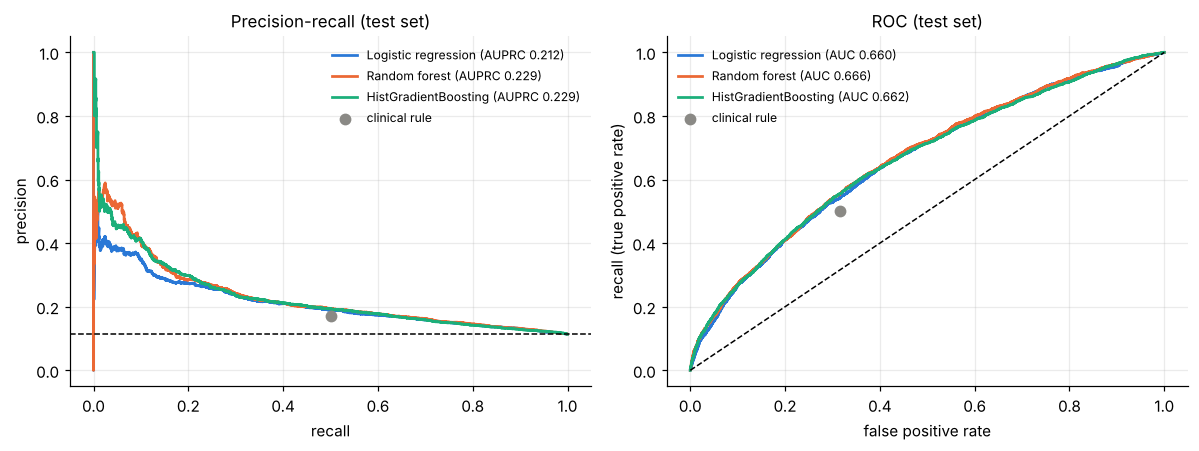

In [16]:
# ---- PR and ROC curves on the test set ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for n in ML_NAMES:
    pr, rc, _ = precision_recall_curve(y_te, test_scores[n]); axes[0].plot(rc, pr, color=colors[n], lw=1.8, label=f"{n} (AUPRC {ap(y_te, test_scores[n]):.3f})")
    fpr, tpr, _ = roc_curve(y_te, test_scores[n]);            axes[1].plot(fpr, tpr, color=colors[n], lw=1.8, label=f"{n} (AUC {roc_auc_score(y_te, test_scores[n]):.3f})")
m = operating_metrics(y_te, rule_test)
axes[0].scatter(m["recall"], m["precision"], color=C_GREY, s=45, zorder=5, label="clinical rule")
axes[1].scatter(m["FP"] / (m["FP"] + m["TN"]), m["recall"], color=C_GREY, s=45, zorder=5, label="clinical rule")
axes[0].axhline(y_te.mean(), color="black", ls="--", lw=1); axes[1].plot([0, 1], [0, 1], color="black", ls="--", lw=1)
axes[0].set(xlabel="recall", ylabel="precision", title="Precision-recall (test set)")
axes[1].set(xlabel="false positive rate", ylabel="recall (true positive rate)", title="ROC (test set)")
for a in axes: a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "test_curves.png", dpi=150); plt.show()

## 13. Error analysis — where does the model fail?

We look at the selected model at its cost-optimal threshold, by subgroup. We compare

- **flagged share** (are some groups flagged more often?),
- **recall** (of the patients who really come back, how many do we catch?) and **false-positive rate**,
- **calibration** (mean predicted risk vs. observed rate): does the same score mean the same risk in each group?

Race is not a model input here, but it is used for this audit. Small groups give noisy numbers — read the `n` and `positives` columns.

In [17]:
age_band = pd.cut(X_test["age_num"], [0, 40, 60, 80, 100], labels=["<40", "40-59", "60-79", "80+"], right=False)
race_grp = X_test["race"].replace({"Other": "Other / unknown", "Unknown": "Other / unknown"})
audit = {"age": age_band.astype(str), "gender": X_test["gender"], "race": race_grp,
         "discharge destination": X_test["discharge_group"], "prior inpatient stays": X_test["number_inpatient"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"})}

rows = []
flags = sel_p >= THRESHOLD
for dim, labels in audit.items():
    labels = labels.to_numpy()
    for g in sorted(set(labels)):
        idx = labels == g
        yy, pp, ff = y_te[idx], sel_p[idx], flags[idx]
        c = confusion_counts(yy, ff)
        if idx.sum() < 100: continue
        rows.append({"dimension": dim, "group": g, "n": int(idx.sum()), "positives": int(yy.sum()),
                     "observed rate": yy.mean(), "mean predicted": pp.mean(), "flagged share": ff.mean(),
                     "recall": c["TP"] / max(c["TP"] + c["FN"], 1), "FPR": c["FP"] / max(c["FP"] + c["TN"], 1),
                     "precision": c["TP"] / max(c["TP"] + c["FP"], 1),
                     "AUROC": roc_auc_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan})
subgroups = pd.DataFrame(rows).set_index(["dimension", "group"])
subgroups.round(3).to_csv(RESULTS / "subgroup_analysis.csv")
subgroups.round(3)

n  positives  observed rate  mean predicted  flagged share  recall    FPR  precision  AUROC
dimension             group                                                                                                                       
age                   40-59                         5329        533          0.100           0.105          0.159   0.366  0.136      0.231  0.679
                      60-79                         9516       1110          0.117           0.116          0.176   0.335  0.155      0.222  0.653
                      80+                           3808        491          0.129           0.123          0.183   0.295  0.167      0.208  0.618
                      <40                           1214        129          0.106           0.107          0.175   0.481  0.139      0.291  0.730
gender                Female                       10531       1207          0.115           0.115          0.175   0.342  0.153      0.224  0.663
                      Male                          9336       1056          0.113           0.113          0.170   0.342  0.148      0.228  0.661
race                  AfricanAmerican               3758        407          0.108           0.113          0.186   0.369  0.164      0.215  0.666
                      Asian                          114         11          0.096           0.100          0.123   0.091  0.126      0.071  0.693
                      Caucasian                    14826       1731          0.117           0.115          0.174   0.343  0.152      0.229  0.659
                      Hispanic                       378         43          0.114           0.112          0.177   0.419  0.146      0.269  0.754
                      Other / unknown                791         71          0.090           0.096          0.080   0.169  0.071      0.190  0.639
discharge destination Home                         11991       1121          0.093           0.094          0.109   0.254  0.094      0.218  0.647
                      Home with health service      2611        337          0.129           0.128          0.184   0.320  0.164      0.225  0.633
                      Left against medical advice    118         16          0.136           0.146          0.288   0.375  0.275      0.176  0.589
                      Nursing / long-term care      3089        446          0.144           0.141          0.232   0.323  0.217      0.201  0.592
                      Other facility / transfer      728        140          0.192           0.175          0.493   0.686  0.447      0.267  0.671
                      Rehabilitation                 400        110          0.275           0.246          0.982   1.000  0.976      0.280  0.668
                      Unknown                        930         93          0.100           0.125          0.149   0.269  0.136      0.180  0.633
prior inpatient stays 0                            13177       1127          0.086           0.088          0.032   0.089  0.026      0.239  0.613
                      1                             3828        520          0.136           0.131          0.118   0.198  0.106      0.227  0.614
                      2+                            2862        616          0.215           0.210          0.893   0.927  0.884      0.223  0.622

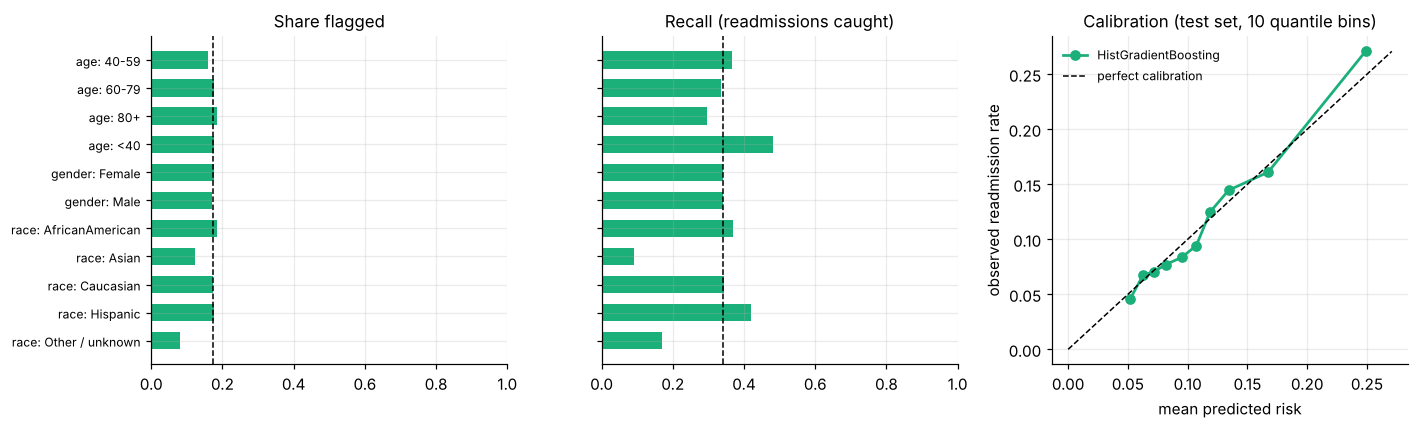

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
plot_df = subgroups.loc[["age", "gender", "race"]].reset_index()
labels = plot_df["dimension"] + ": " + plot_df["group"]
y_pos = np.arange(len(plot_df))
for ax, col, title in [(axes[0], "flagged share", "Share flagged"), (axes[1], "recall", "Recall (readmissions caught)")]:
    ax.barh(y_pos, plot_df[col], color=colors[SELECTED], height=0.62)
    ax.set_yticks(y_pos); ax.set_yticklabels(labels, fontsize=8); ax.invert_yaxis(); ax.set_title(title); ax.set_xlim(0, 1)
    ax.axvline(flags.mean() if col == "flagged share" else operating_metrics(y_te, flags)["recall"], color="black", ls="--", lw=1)
axes[1].set_yticklabels([])
# reliability diagram (overall)
frac_pos, mean_pred = calibration_curve(y_te, sel_p, n_bins=10, strategy="quantile")
axes[2].plot(mean_pred, frac_pos, marker="o", color=colors[SELECTED], lw=1.8, label=SELECTED)
axes[2].plot([0, max(mean_pred.max(), frac_pos.max())], [0, max(mean_pred.max(), frac_pos.max())], color="black", ls="--", lw=1, label="perfect calibration")
axes[2].set(xlabel="mean predicted risk", ylabel="observed readmission rate", title="Calibration (test set, 10 quantile bins)"); axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "error_analysis.png", dpi=150); plt.show()

## 14. What drives the predictions?

**Logistic regression:** coefficients (log-odds) of the final fitted model. Numeric inputs are standardised, so a coefficient is the change in log-odds per +1 SD; dummies show the change when the category is present.

**Which block of information matters?** Permutation importance of whole *blocks*: on one **held-out CV fold of the training data** (not the test set), we shuffle all columns of a block jointly and record how much AUPRC drops. A big drop means the model relies on that block. (Correlated features share credit, so read it as "how much does the model lose without this information", not as causal effect.)

Logistic regression (Lasso): 73 of 128 coefficients non-zero


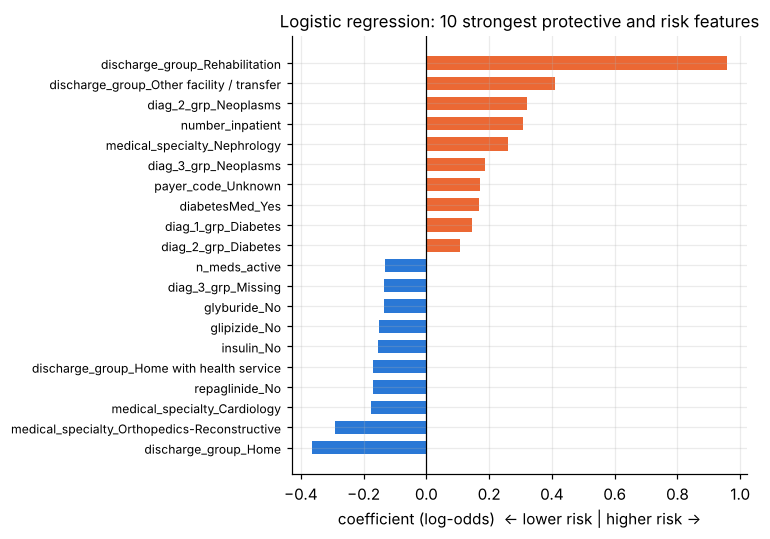

In [19]:
lr_pipe = models["Logistic regression"]["estimator"]
names = lr_pipe.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps["clf"].coef_[0], index=[n.split("__", 1)[1] for n in names]).sort_values()
nz = (coefs != 0).sum()
print(f"Logistic regression ({'Lasso' if models['Logistic regression']['penalty'] == 'l1' else 'Ridge'}): {nz} of {len(coefs)} coefficients non-zero")

top = pd.concat([coefs.head(10), coefs.tail(10)])
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=[C_BLUE if v < 0 else C_ORANGE for v in top.values], height=0.65)
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("coefficient (log-odds)  <- lower risk | higher risk ->")
ax.set_title("Logistic regression: 10 strongest protective and risk features"); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "logit_coefficients.png", dpi=150); plt.show()

HistGradientBoosting: AUPRC on the held-out fold = 0.2600


,AUPRC drop,SD
block,,
Prior utilisation,0.1115,0.0026
Current stay,0.0503,0.0018
Admission context,0.0133,0.0014
Diagnoses,0.0108,0.0029
Diabetes medication,0.0054,0.0016
Demographics,0.0018,0.0005
Lab tests,0.0007,0.0004


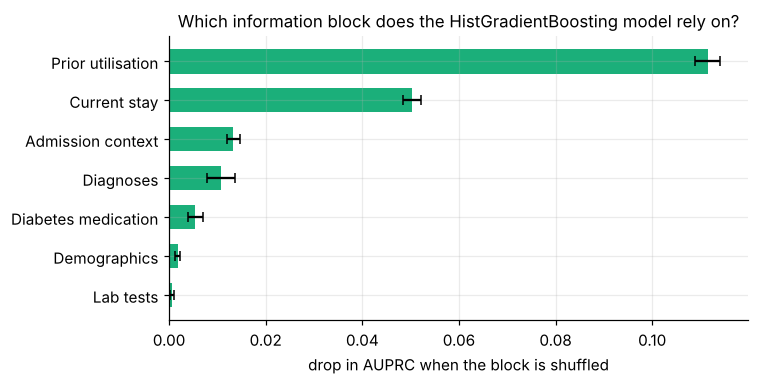

In [20]:
def block_permutation_importance(est, X_val, y_val, blocks, n_repeats=5, seed=SEED):
    rng = np.random.default_rng(seed)
    base = ap(y_val, est.predict_proba(X_val)[:, 1])
    out = []
    for name, cols in blocks.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X_val.copy(); perm = rng.permutation(len(Xp))
            for c in cols:
                Xp[c] = X_val[c].to_numpy()[perm]          # same row permutation for the whole block
            drops.append(base - ap(y_val, est.predict_proba(Xp)[:, 1]))
        out.append((name, np.mean(drops), np.std(drops, ddof=1)))
    return base, pd.DataFrame(out, columns=["block", "AUPRC drop", "SD"]).set_index("block").sort_values("AUPRC drop", ascending=False)

tr0, va0 = cv_splits[0]                                   # held-out fold of the TRAINING data
est0 = clone(models[SELECTED]["estimator"]).fit(X_train.iloc[tr0], y_train.iloc[tr0])
base_ap, block_imp = block_permutation_importance(est0, X_train.iloc[va0], y_train.iloc[va0], BLOCKS, n_repeats=3 if QUICK else 5)
print(f"{SELECTED}: AUPRC on the held-out fold = {base_ap:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
bi = block_imp.sort_values("AUPRC drop")
ax.barh(bi.index, bi["AUPRC drop"], xerr=bi["SD"], color=colors[SELECTED], height=0.62, capsize=3)
ax.set_xlabel("drop in AUPRC when the block is shuffled"); ax.set_title(f"Which information block does the {SELECTED} model rely on?")
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "block_importance.png", dpi=150); plt.show()
block_imp.round(4)

## 15. Limits and save the numbers for the slides

**Limits** (for the slide "When would this model fail?")

- **Weak signal.** Readmission is hard to predict from administrative data; AUROC around 0.65–0.70 is typical in the literature. The model *ranks* patients better than chance and better than the rule, but most flagged patients will not be readmitted (low precision). It supports prioritising follow-up; it should not drive clinical decisions on its own.
- **Old, US-only data** (130 hospitals, 1999–2008): practice, coding and populations have changed. A time-based validation was impossible (no dates); the model must be re-validated on current local data before any use.
- **Readmissions elsewhere are invisible:** a patient readmitted to another hospital counts as "not readmitted", so true rates are underestimated.
- **Timing of diagnoses:** ICD-9 diagnosis codes are often finalised after discharge. If they are not available at the bedside, the diagnosis block must be dropped or approximated.
- **Several encounters per patient:** we keep them all (patient-grouped splits, patient-level bootstrap). Frequent patients influence the fit more than occasional ones.
- **Fairness:** race is not an input, but proxies (payer, specialty, admission source) may encode it. Section 13 audits recall and flag rates by group; small groups are noisy. Before deployment: audit on local data, check calibration per group, and measure whether the follow-up programme actually helps.
- **Assumed costs.** The cost ratio and the 20% capacity are illustrations (Section 0); the operating point should be set together with the hospital.

**Before deploying we would:** validate prospectively on recent data; check calibration and subgroup errors again; run a pilot where follow-up is randomised among flagged patients to measure whether it prevents readmissions.

In [21]:
run_info = {
    "seed": SEED, "outcome": OUTCOME, "boosting_backend": BOOST_NAME, "selected_model": SELECTED,
    "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
    "n_train": int(len(y_train)), "n_test": int(len(y_te)), "patients_train": int(g_train.nunique()), "patients_test": int(g_test.nunique()),
    "base_rate_train": float(y_train.mean()), "base_rate_test": float(y_te.mean()),
    "cost_fn_over_fp": COST_FN_OVER_FP, "flag_share": FLAG_SHARE, "threshold": float(THRESHOLD),
    "best_params": {n: {k.replace("clf__", ""): (v if isinstance(v, (int, float, str)) else str(v)) for k, v in m["params"].items()} for n, m in models.items()},
}
(RESULTS / "run_info.json").write_text(json.dumps(run_info, indent=2))
print("Saved to ./results: cv_summary.csv, test_summary.csv, operating_points_test.csv, subgroup_analysis.csv, run_info.json, figures/*.png")
print("Selected model:", SELECTED, "| boosting backend:", BOOST_NAME)

Saved to ./results: cv_summary.csv, test_summary.csv, operating_points_test.csv, subgroup_analysis.csv, run_info.json, figures/*.png
Selected model: HistGradientBoosting | boosting backend: HistGradientBoosting


### Slide map (Step 4 of the project brief → notebook sections)

| Slide point | Notebook |
|---|---|
| 1. Problem statement and relevance | Title, Section 5 (error costs) |
| 2. Data (source, unit, features) | Sections 1–3 |
| 3. Model (baseline, model classes, why) | Sections 5, 7, 8, 9 |
| 4. Validation (split, leakage) | Sections 3, 4, 6 |
| 5. Performance vs. baseline, with uncertainty | Sections 10, 12 |
| 6. Limits | Sections 13, 15 |